# Ai2020 기반 DFN 구축 흐름: S1 → S2

이 노트북은 Cell 6-6 July-BOL 실험에 대해 다음 두 단계를 한 파일에서 재현한다.

- **S1 — Ai2020 원형:** PyBaMM `Ai2020` parameter set, 원 OCP, 논문 stoichiometry window를 그대로 사용한다.
- **S2 — De 단위 보정 + window 최적화:** 전극 OCP와 나머지 동적 파라미터는 Ai2020 그대로 두고, 전해질 확산계수 (D_e)의 단위를 SI로 보정한 뒤 C/50 qOCV에 맞춰 stoichiometry window를 최적화한다. 최적 window가 뜻하는 (Q_n,Q_p)는 공통 overlap 면적 기준의 (c_{s,\max})로 일관되게 반영한다.

여기까지는 **동적 kinetic/transport fitting이 아니다.** 0.5C, 1C, 2C 충·방전 6개 분기는 오직 S1/S2의 고정 파라미터로 교차검증한다.

> 표기: (x)는 graphite 음극 stoichiometry, (y)는 LCO 양극 stoichiometry다. 충전 시 (x)는 증가하고 (y)는 감소한다.


## Ai2020을 출발점으로만 사용하는 이유

원 논문은 LCO–graphite Enertech pouch cell의 **전압·온도·두께 변화와 전극 입자 응력 불균일성**을 설명하기 위한 electrochemical–thermal–mechanical P2D 모델이다. 논문 Table III은 geometry, porosity, active fraction, (c_{s,\max}), stoichiometric endpoints 등을 제시하지만, OCP는 별도 문헌에서 가져왔고 PyBaMM 구현의 고체 확산계수와 교환전류밀도 함수도 Dualfoil 계열 값을 사용한다. 즉, 현재 대상 셀에 대해 모든 전기화학 파라미터가 독립적으로 재측정된 세트는 아니다.

특히 논문의 실험 비교는 0.5C, 1C, 2C **방전**까지이며, 제조사가 제시한 최대 충전율은 1C라고 명시되어 있다. 2C cycling 계산은 포함되지만, 고율 충전 전압과 음극전위 또는 Li plating 제약을 직접 검증한 연구는 아니다. 따라서 Ai2020은 좋은 물리 기반 초기값이지만, 원 세트를 그대로 고속충전 프로토콜 최적화의 최종 모델로 간주하는 것은 검증 범위를 벗어난다.

| 파라미터 묶음 | Ai2020/PyBaMM에서의 출처 | 현재 과제에서의 의미 |
|---|---|---|
| Geometry, porosity, active fraction, (c_{s,\max}), endpoints | Ai2020 Table III 및 선행 Enertech 연구 | 대상 셀 독립 측정값이 아닌 초기값 |
| 음극·양극 OCP | 선행문헌의 Enertech graphite/LCO 곡선 | charge/discharge 방향별 OCP가 아니라 single equilibrium OCP |
| (D_{s,n},D_{s,p}) | PyBaMM Ai2020 구현에서 Dualfoil 상수 | 대상 셀 GITT 측정값이 아님 |
| (k_n,k_p) 함수 | PyBaMM Ai2020 구현에서 Dualfoil 계열 식 | 대상 셀 EIS/HPPC 식별값이 아님 |
| (D_e,\kappa,t_+^0,\chi) | 문헌 기반 전해질 상관식 | 실제 사용 전해질 조성과 직접 일치한다고 단정할 수 없음 |

근거 자료:

- [Ai et al., Journal of The Electrochemical Society 167 (2020) 013512](https://doi.org/10.1149/2.0122001JES) — 연구 목적, Table III, 방전 검증 범위와 셀 운전 제한.
- [PyBaMM 공식 Enertech/Ai2020 검증 예제](https://docs.pybamm.org/en/latest/source/examples/notebooks/models/Validating_mechanical_models_Enertech_DFN.html) — `ParameterValues("Ai2020")`, DFN, 0.5/1/2C 방전 재현 흐름.
- [PyBaMM 공식 parameter-set API](https://docs.pybamm.org/en/latest/source/api/parameters/parameter_sets.html) — 내장 parameter set 사용 방식.
- [Valøen & Reimers, JES 152 (2005) A882](https://doi.org/10.1149/1.1872737) — Ai2020 계열 구현에서 사용하는 전해질 수송 상관식의 원 출처.

이 노트북의 결론은 “Ai2020 논문이 부적절하다”가 아니라, **원래 목적과 검증 영역이 고속충전 제어용 모델과 다르므로 대상 셀 데이터로 단계별 보정·검증이 필요하다**는 뜻이다.


In [1]:
# =====================================================================
# 0. 실행 환경과 공통 설정
# =====================================================================
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("PYBAMM_DISABLE_TELEMETRY", "true")
os.environ.setdefault("PYBAMM_TELEMETRY", "false")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
import pybamm.input.parameters.lithium_ion.Ai2020 as ai2020_source
from IPython.display import display
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import differential_evolution, minimize

warnings.filterwarnings("ignore", message="Workbook contains no default style")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)


def find_repository_root(start: Path) -> Path:
    """Find the repository that contains AGENTS.md and the tracked input workbook."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / "AGENTS.md").exists()
            and (candidate / "260902 Enertech셀 데이터 모음.xlsx").exists()
        ):
            return candidate
    raise FileNotFoundError(
        "저장소 루트를 찾지 못했습니다. 이 notebook을 repository 내부에서 실행하세요."
    )


repository_root = find_repository_root(Path.cwd())
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

result_directory = repository_root / "results" / "261019_s1_s2_fitting_notebook"
result_directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 261019
FARADAY_CONSTANT_C_PER_MOL = 96485.33212
NOMINAL_CELL_CAPACITY_AH = 2.28
TESTED_C_RATES = (0.5, 1.0, 2.0)

print(f"Repository : {repository_root}")
print(f"PyBaMM     : {pybamm.__version__}")
print(f"Results    : {result_directory}")


Repository : C:\Users\user\Documents\Codex\2026-10-07\https-github-com-rinny-hi-ai2020\work\repo
PyBaMM     : 26.7.1.0
Results    : C:\Users\user\Documents\Codex\2026-10-07\https-github-com-rinny-hi-ai2020\work\repo\results\261019_s1_s2_fitting_notebook


## 1. 실험 데이터 구성

Stoichiometry window fitting에는 2026-06 C/50 저율 시험의 cell-1, cell-2를 사용한다. 각 셀에서 완전한 cycle 2–5의 충전 4개와 방전 4개를 선택하므로 총 **충전 8개 + 방전 8개**다.

1. 각 branch를 자체 종료용량으로 0–100% SOC에 정규화한다.
2. 충전 8개와 방전 8개를 각각 평균한다.
3. 두 방향 평균의 중간값을 qOCV로 정의한다.
4. Full-cell 기준용량은 8개 충전용량 평균과 8개 방전용량 평균의 평균이다.

동적 검증은 저장소의 `260902 Enertech셀 데이터 모음.xlsx`에 정리된 Cell 6-6 July-BOL 0.5C/1C/2C 충·방전 branch를 사용한다. 원본 부재 시 다른 데이터를 묵시적으로 대체하지 않고 즉시 오류를 낸다.


In [2]:
# =====================================================================
# 1. C/50 qOCV와 0.5C/1C/2C 검증 데이터 불러오기
# =====================================================================
default_low_rate_files = [
    Path(
        r"C:\Users\user\OneDrive\01. 적응형 충전 프로토콜\4. Enertech 파우치셀 실험데이터"
        r"\260610 파우치셀 데이터\260610 저율데이터 1.xlsx"
    ),
    Path(
        r"C:\Users\user\OneDrive\01. 적응형 충전 프로토콜\4. Enertech 파우치셀 실험데이터"
        r"\260610 파우치셀 데이터\260610 저율데이터 2.xlsx"
    ),
]
missing_low_rate_files = [path for path in default_low_rate_files if not path.exists()]
if missing_low_rate_files:
    missing_text = "\n".join(str(path) for path in missing_low_rate_files)
    raise FileNotFoundError(
        "Stoichiometry window를 다시 fitting하려면 다음 C/50 원본이 필요합니다:\n"
        + missing_text
        + "\n필요하면 이 셀의 default_low_rate_files를 실제 위치로 수정하세요."
    )

def clean_and_sort_curve(horizontal_axis, vertical_axis):
    horizontal_axis = np.asarray(horizontal_axis, dtype=float)
    vertical_axis = np.asarray(vertical_axis, dtype=float)
    valid = np.isfinite(horizontal_axis) & np.isfinite(vertical_axis)
    horizontal_axis = horizontal_axis[valid]
    vertical_axis = vertical_axis[valid]
    order = np.argsort(horizontal_axis, kind="stable")
    unique_axis, unique_index = np.unique(
        horizontal_axis[order], return_index=True
    )
    return unique_axis, vertical_axis[order][unique_index]


def build_c50_qocv_target(low_rate_files, full_cell_soc):
    """Average complete C/50 cycles 2--5 from two cells."""
    charge_voltage_curves = []
    discharge_voltage_curves = []
    charge_capacities_ah = []
    discharge_capacities_ah = []

    for workbook_path in low_rate_files:
        record = pd.read_excel(workbook_path, sheet_name="record")
        step_type = record["Step Type"].astype(str)
        contiguous_group = step_type.ne(step_type.shift()).cumsum()
        branches = {"CC Chg": [], "CC DChg": []}

        for _, branch in record.groupby(contiguous_group):
            branch_type = str(branch["Step Type"].iloc[0])
            if branch_type not in branches:
                continue
            capacity_ah = pd.to_numeric(
                branch["Capacity(Ah)"], errors="coerce"
            ).to_numpy(dtype=float)
            voltage_v = pd.to_numeric(
                branch["Voltage(V)"], errors="coerce"
            ).to_numpy(dtype=float)
            median_current_a = float(
                pd.to_numeric(branch["Current(A)"], errors="coerce").median()
            )
            valid = np.isfinite(capacity_ah) & np.isfinite(voltage_v)
            capacity_ah, voltage_v = capacity_ah[valid], voltage_v[valid]
            if (
                len(capacity_ah) < 50
                or float(np.max(capacity_ah)) < 2.2
                or abs(median_current_a) > 0.06
            ):
                continue

            branch_capacity_ah = float(np.max(capacity_ah))
            branch_soc = (
                capacity_ah / branch_capacity_ah
                if branch_type == "CC Chg"
                else 1.0 - capacity_ah / branch_capacity_ah
            )
            clean_soc, clean_voltage = clean_and_sort_curve(
                branch_soc, voltage_v
            )
            interpolated_voltage = np.interp(
                full_cell_soc, clean_soc, clean_voltage
            )
            branches[branch_type].append(
                (branch_capacity_ah, interpolated_voltage)
            )

        # 첫 방전은 부분 초기충전 직후이므로 제외하고 complete cycles 2--5를 맞춘다.
        selected_charge = branches["CC Chg"]
        selected_discharge = branches["CC DChg"][1:]
        for capacity_ah, voltage_v in selected_charge:
            charge_capacities_ah.append(capacity_ah)
            charge_voltage_curves.append(voltage_v)
        for capacity_ah, voltage_v in selected_discharge:
            discharge_capacities_ah.append(capacity_ah)
            discharge_voltage_curves.append(voltage_v)

    mean_charge_voltage = np.mean(charge_voltage_curves, axis=0)
    mean_discharge_voltage = np.mean(discharge_voltage_curves, axis=0)
    mean_charge_capacity = float(np.mean(charge_capacities_ah))
    mean_discharge_capacity = float(np.mean(discharge_capacities_ah))
    return {
        "charge": mean_charge_voltage,
        "discharge": mean_discharge_voltage,
        "qocv": 0.5 * (mean_charge_voltage + mean_discharge_voltage),
        "qcell": 0.5 * (mean_charge_capacity + mean_discharge_capacity),
        "charge_capacity_mean": mean_charge_capacity,
        "discharge_capacity_mean": mean_discharge_capacity,
        "n_charge": len(charge_capacities_ah),
        "n_discharge": len(discharge_capacities_ah),
    }


def load_dynamic_validation_data(dynamic_frame, reference_capacity_ah):
    """Build six validation branches using the original Q/Qcell SOC definition."""
    output = {}
    for c_rate in TESTED_C_RATES:
        for is_charge in (True, False):
            direction = "charge" if is_charge else "discharge"
            selected = dynamic_frame[
                np.isclose(
                    pd.to_numeric(dynamic_frame["rate_C"], errors="coerce"),
                    c_rate,
                )
                & (dynamic_frame["direction"].astype(str).str.lower() == direction)
            ].copy()
            if len(selected) <= 5:
                raise RuntimeError(f"Dynamic data missing: {c_rate}C {direction}")
            capacity_ah = pd.to_numeric(
                selected["Q_Ah"], errors="coerce"
            ).to_numpy(dtype=float)
            capacity_ah = capacity_ah - capacity_ah[0]
            branch_soc = (
                capacity_ah / reference_capacity_ah
                if is_charge
                else 1.0 - capacity_ah / reference_capacity_ah
            )
            output[(c_rate, is_charge)] = {
                "t_min": pd.to_numeric(
                    selected["t_min"], errors="coerce"
                ).to_numpy(dtype=float),
                "V": pd.to_numeric(
                    selected["V_V"], errors="coerce"
                ).to_numpy(dtype=float),
                "I_A": pd.to_numeric(
                    selected["I_A"], errors="coerce"
                ).to_numpy(dtype=float),
                "Q_Ah": capacity_ah,
                "SOC": np.clip(branch_soc, 0.0, 1.0),
            }
    return output


state_of_charge_grid = np.linspace(0.0, 1.0, 1001)
low_rate_target = build_c50_qocv_target(
    default_low_rate_files, state_of_charge_grid
)
full_cell_capacity_ah = float(low_rate_target["qcell"])

tracked_input_workbook = repository_root / "260902 Enertech셀 데이터 모음.xlsx"
dynamic_frame = pd.read_excel(
    tracked_input_workbook, sheet_name="DYNAMIC", header=8
)
dynamic_experiment = load_dynamic_validation_data(
    dynamic_frame, full_cell_capacity_ah
)

low_rate_summary = pd.DataFrame(
    {
        "항목": [
            "선택 충전 branch 수",
            "선택 방전 branch 수",
            "평균 충전용량 [Ah]",
            "평균 방전용량 [Ah]",
            "Full-cell 기준용량 [Ah]",
        ],
        "값": [
            int(low_rate_target["n_charge"]),
            int(low_rate_target["n_discharge"]),
            float(low_rate_target["charge_capacity_mean"]),
            float(low_rate_target["discharge_capacity_mean"]),
            full_cell_capacity_ah,
        ],
    }
)
display(low_rate_summary)


,항목,값
0,선택 충전 branch 수,8.000000
1,선택 방전 branch 수,8.000000
2,평균 충전용량 [Ah],2.355758
3,평균 방전용량 [Ah],2.357298
4,Full-cell 기준용량 [Ah],2.356528


## 2. S1 정의와 S2 stoichiometry-window 목적함수

S1은 논문 window를 그대로 사용한다.

\[
x_0=0.0065,\quad x_{100}=0.8400,\quad
y_0=0.9651,\quad y_{100}=0.4350
\]

S2에서는 Ai2020의 음극·양극 OCP를 유지하고 다음 식으로 C/50 qOCV를 fitting한다.

\[
V_{\mathrm{OCV}}(z)=U_p\!\left(y_0-z(y_0-y_{100})\right)
-U_n\!\left(x_0+z(x_{100}-x_0)\right)
\]

목적함수는 endpoint 노이즈의 과도한 영향만 줄이기 위해 SOC 2–98%의 전압 MSE다. 다만 endpoint를 방치하지 않도록 SOC 0%, 100% 전압오차를 각각 10 mV 이하로 제한한다. 또한 (Q_n=Q_{cell}/\Delta x), (Q_p=Q_{cell}/\Delta y)가 2.4–6.0 Ah 범위에 있도록 window 폭을 제한한다. 전역 탐색 후 SLSQP로 다듬으며 random seed를 고정한다.


In [3]:
# =====================================================================
# 2. Ai2020 원 OCP와 읽기 쉬운 stoichiometry-window fitting 함수
# =====================================================================
ai2020_parameters = pybamm.ParameterValues("Ai2020")


def build_ocp_detail_from_packaged_data(packaged_ocp_data: tuple) -> dict:
    """Convert PyBaMM's packaged OCP table to a clean interpolation grid."""
    _, (raw_stoichiometry, raw_voltage) = packaged_ocp_data
    stoichiometry = np.asarray(raw_stoichiometry, dtype=float).reshape(-1)
    voltage = np.asarray(raw_voltage, dtype=float).reshape(-1)
    order = np.argsort(stoichiometry)
    unique_stoichiometry, unique_index = np.unique(
        stoichiometry[order], return_index=True
    )
    unique_voltage = voltage[order][unique_index]
    interpolation_grid = np.linspace(
        float(unique_stoichiometry.min()),
        float(unique_stoichiometry.max()),
        3001,
    )
    interpolated_voltage = np.interp(
        interpolation_grid, unique_stoichiometry, unique_voltage
    )
    return {
        "grid": interpolation_grid,
        "equilibrium": interpolated_voltage,
        "lithiation": interpolated_voltage.copy(),
        "delithiation": interpolated_voltage.copy(),
        "directional_complete": False,
        "absolute_anchor": True,
    }


ai2020_negative_ocp = build_ocp_detail_from_packaged_data(
    ai2020_source.graphite_ocp_Enertech_Ai2020_data
)
ai2020_positive_ocp = build_ocp_detail_from_packaged_data(
    ai2020_source.lico2_ocp_Ai2020_data
)

ai2020_published_window = {
    "x0": 0.0065,
    "x100": 0.8400,
    "y0": 0.9651,
    "y100": 0.4350,
}


def predict_full_cell_ocv(
    window_vector: np.ndarray,
    full_cell_soc: np.ndarray,
    negative_ocp: dict,
    positive_ocp: dict,
) -> np.ndarray:
    """Predict full-cell OCV from electrode OCPs and four window endpoints."""
    negative_at_zero_soc, negative_at_full_soc, positive_at_full_soc, positive_at_zero_soc = (
        map(float, window_vector)
    )
    negative_stoichiometry = negative_at_zero_soc + full_cell_soc * (
        negative_at_full_soc - negative_at_zero_soc
    )
    positive_stoichiometry = positive_at_zero_soc - full_cell_soc * (
        positive_at_zero_soc - positive_at_full_soc
    )
    negative_voltage = np.interp(
        negative_stoichiometry,
        negative_ocp["grid"],
        negative_ocp["equilibrium"],
    )
    positive_voltage = np.interp(
        positive_stoichiometry,
        positive_ocp["grid"],
        positive_ocp["equilibrium"],
    )
    return positive_voltage - negative_voltage


def fit_stoichiometry_window(
    target_voltage: np.ndarray,
    full_cell_soc: np.ndarray,
    measured_cell_capacity_ah: float,
    negative_ocp: dict,
    positive_ocp: dict,
    random_seed: int,
) -> tuple[np.ndarray, dict]:
    """Fit x0, x100, y100, y0 with explicit physical constraints."""
    negative_minimum = float(np.min(negative_ocp["grid"]))
    negative_maximum = float(np.max(negative_ocp["grid"]))
    positive_minimum = float(np.min(positive_ocp["grid"]))
    positive_maximum = float(np.max(positive_ocp["grid"]))

    # Qelectrode = Qcell / delta_stoichiometry.  The 2.4--6.0 Ah prior
    # becomes these lower/upper bounds for delta_x and delta_y.
    minimum_window_width = measured_cell_capacity_ah / 6.0
    maximum_window_width = measured_cell_capacity_ah / 2.4
    fitting_mask = (full_cell_soc >= 0.02) & (full_cell_soc <= 0.98)

    def voltage_mean_squared_error(window_vector: np.ndarray) -> float:
        predicted_voltage = predict_full_cell_ocv(
            window_vector, full_cell_soc, negative_ocp, positive_ocp
        )
        voltage_error = predicted_voltage - target_voltage
        return float(np.mean(voltage_error[fitting_mask] ** 2))

    def squared_constraint_violation(window_vector: np.ndarray) -> float:
        negative_at_zero_soc, negative_at_full_soc, positive_at_full_soc, positive_at_zero_soc = (
            map(float, window_vector)
        )
        negative_width = negative_at_full_soc - negative_at_zero_soc
        positive_width = positive_at_zero_soc - positive_at_full_soc
        endpoint_prediction = predict_full_cell_ocv(
            window_vector,
            full_cell_soc[[0, -1]],
            negative_ocp,
            positive_ocp,
        )
        endpoint_error = endpoint_prediction - target_voltage[[0, -1]]
        violations = [
            max(0.0, minimum_window_width - negative_width),
            max(0.0, negative_width - maximum_window_width),
            max(0.0, minimum_window_width - positive_width),
            max(0.0, positive_width - maximum_window_width),
            max(0.0, abs(float(endpoint_error[0])) - 0.010),
            max(0.0, abs(float(endpoint_error[1])) - 0.010),
        ]
        return float(np.sum(np.square(violations)))

    def penalized_objective(window_vector: np.ndarray) -> float:
        return voltage_mean_squared_error(window_vector) + 1e4 * squared_constraint_violation(
            window_vector
        )

    bounds = [
        (negative_minimum, negative_maximum),
        (negative_minimum, negative_maximum),
        (positive_minimum, positive_maximum),
        (positive_minimum, positive_maximum),
    ]
    global_result = differential_evolution(
        penalized_objective,
        bounds=bounds,
        seed=random_seed,
        popsize=16,
        maxiter=350,
        tol=1e-10,
        polish=False,
        workers=1,
    )

    constraints = [
        {
            "type": "ineq",
            "fun": lambda window: (window[1] - window[0]) - minimum_window_width,
        },
        {
            "type": "ineq",
            "fun": lambda window: maximum_window_width - (window[1] - window[0]),
        },
        {
            "type": "ineq",
            "fun": lambda window: (window[3] - window[2]) - minimum_window_width,
        },
        {
            "type": "ineq",
            "fun": lambda window: maximum_window_width - (window[3] - window[2]),
        },
        {
            "type": "ineq",
            "fun": lambda window: 0.010
            - abs(
                float(
                    predict_full_cell_ocv(
                        window, full_cell_soc[[0]], negative_ocp, positive_ocp
                    )[0]
                    - target_voltage[0]
                )
            ),
        },
        {
            "type": "ineq",
            "fun": lambda window: 0.010
            - abs(
                float(
                    predict_full_cell_ocv(
                        window, full_cell_soc[[-1]], negative_ocp, positive_ocp
                    )[0]
                    - target_voltage[-1]
                )
            ),
        },
    ]
    local_result = minimize(
        voltage_mean_squared_error,
        x0=global_result.x,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 3000, "ftol": 1e-14, "disp": False},
    )
    fitted_window = (
        local_result.x
        if squared_constraint_violation(local_result.x)
        <= squared_constraint_violation(global_result.x) + 1e-12
        else global_result.x
    )
    diagnostics = {
        "optimizer_success": bool(local_result.success),
        "optimizer_message": str(local_result.message),
        "constraint_violation": squared_constraint_violation(fitted_window),
    }
    return np.asarray(fitted_window, dtype=float), diagnostics


,Stage,x0,x100,y0,y100,delta_x,delta_y,Qn_Ah,Qp_Ah,qOCV_RMSE_2_98_mV
0,S1 Ai2020 published,0.006500,0.840000,0.965100,0.435000,0.833500,0.530100,NaN,NaN,39.844264
1,S2 fitted on Ai2020 OCP,0.003224,0.985111,0.867309,0.441938,0.981887,0.425371,2.4,5.539929,16.444361


{'optimizer_success': True, 'optimizer_message': 'Optimization terminated successfully', 'constraint_violation': 5.323089810354034e-32}


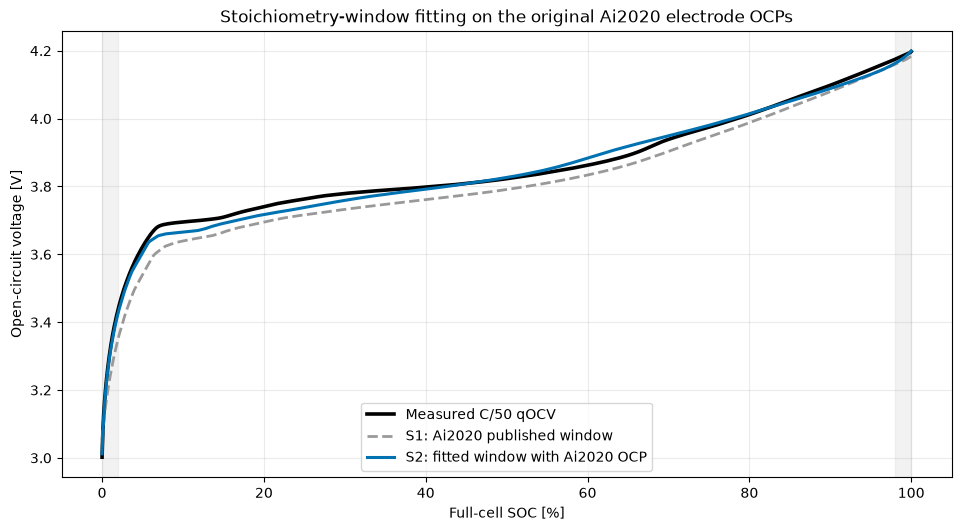

In [4]:
# =====================================================================
# 3. Ai2020 원 OCP에서 window fitting 실행 및 qOCV 적합 확인
# =====================================================================
fitted_window_vector, fitting_diagnostics = fit_stoichiometry_window(
    target_voltage=np.asarray(low_rate_target["qocv"], dtype=float),
    full_cell_soc=state_of_charge_grid,
    measured_cell_capacity_ah=full_cell_capacity_ah,
    negative_ocp=ai2020_negative_ocp,
    positive_ocp=ai2020_positive_ocp,
    random_seed=RANDOM_SEED,
)
fitted_negative_zero, fitted_negative_full, fitted_positive_full, fitted_positive_zero = (
    fitted_window_vector
)
fitted_window = {
    "x0": float(fitted_negative_zero),
    "x100": float(fitted_negative_full),
    "y0": float(fitted_positive_zero),
    "y100": float(fitted_positive_full),
}
fitted_negative_width = fitted_window["x100"] - fitted_window["x0"]
fitted_positive_width = fitted_window["y0"] - fitted_window["y100"]
fitted_negative_capacity_ah = full_cell_capacity_ah / fitted_negative_width
fitted_positive_capacity_ah = full_cell_capacity_ah / fitted_positive_width

fitted_qocv = predict_full_cell_ocv(
    fitted_window_vector,
    state_of_charge_grid,
    ai2020_negative_ocp,
    ai2020_positive_ocp,
)
published_window_vector = np.array(
    [
        ai2020_published_window["x0"],
        ai2020_published_window["x100"],
        ai2020_published_window["y100"],
        ai2020_published_window["y0"],
    ]
)
published_qocv = predict_full_cell_ocv(
    published_window_vector,
    state_of_charge_grid,
    ai2020_negative_ocp,
    ai2020_positive_ocp,
)
fitting_region = (state_of_charge_grid >= 0.02) & (state_of_charge_grid <= 0.98)

window_comparison = pd.DataFrame(
    [
        {
            "Stage": "S1 Ai2020 published",
            **ai2020_published_window,
            "delta_x": ai2020_published_window["x100"] - ai2020_published_window["x0"],
            "delta_y": ai2020_published_window["y0"] - ai2020_published_window["y100"],
            "Qn_Ah": np.nan,
            "Qp_Ah": np.nan,
            "qOCV_RMSE_2_98_mV": 1000
            * np.sqrt(
                np.mean(
                    (
                        published_qocv[fitting_region]
                        - np.asarray(low_rate_target["qocv"])[fitting_region]
                    )
                    ** 2
                )
            ),
        },
        {
            "Stage": "S2 fitted on Ai2020 OCP",
            **fitted_window,
            "delta_x": fitted_negative_width,
            "delta_y": fitted_positive_width,
            "Qn_Ah": fitted_negative_capacity_ah,
            "Qp_Ah": fitted_positive_capacity_ah,
            "qOCV_RMSE_2_98_mV": 1000
            * np.sqrt(
                np.mean(
                    (
                        fitted_qocv[fitting_region]
                        - np.asarray(low_rate_target["qocv"])[fitting_region]
                    )
                    ** 2
                )
            ),
        },
    ]
)
display(window_comparison.round(6))
print(fitting_diagnostics)

figure, axis = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
axis.plot(
    100 * state_of_charge_grid,
    low_rate_target["qocv"],
    color="black",
    linewidth=2.6,
    label="Measured C/50 qOCV",
)
axis.plot(
    100 * state_of_charge_grid,
    published_qocv,
    color="#999999",
    linestyle="--",
    linewidth=2.0,
    label="S1: Ai2020 published window",
)
axis.plot(
    100 * state_of_charge_grid,
    fitted_qocv,
    color="#0072B2",
    linewidth=2.2,
    label="S2: fitted window with Ai2020 OCP",
)
axis.axvspan(0, 2, color="#BBBBBB", alpha=0.18)
axis.axvspan(98, 100, color="#BBBBBB", alpha=0.18)
axis.set(xlabel="Full-cell SOC [%]", ylabel="Open-circuit voltage [V]")
axis.grid(alpha=0.25)
axis.legend()
axis.set_title("Stoichiometry-window fitting on the original Ai2020 electrode OCPs")
figure.savefig(result_directory / "s1_s2_qocv_window_fit.png", dpi=220)
plt.show()


## 3. Window와 DFN inventory를 일관되게 연결

Window만 바꾸고 기존 (c_{s,\max})를 그대로 두면, fitted (Q_n,Q_p)와 DFN 내부의 전극 lithium inventory가 서로 달라진다. 따라서 다음 관계로 (c_{s,\max})를 역산한다.

\[
Q_k=\frac{F A L_k \varepsilon_{s,k}c_{s,\max,k}}{3600},\qquad
c_{s,\max,k}=\frac{3600Q_k}{FAL_k\varepsilon_{s,k}}
\]

여기서 1D DFN의 전류 통과 면적 (A)는 양·음극이 실제로 마주 보는 **공통 overlap 면적**이다. teardown의 작은 양극 footprint (45.4\,\mathrm{mm}\times51.0\,\mathrm{mm})와 34 coated faces를 사용한다. 이 (c_{s,\max})는 독립적인 소재 분석 측정값이 아니라, 가정된 active-material fraction과 geometry 아래에서 fitted (Q_n,Q_p)를 구현하기 위한 **capacity-consistent 역산값**이다.


In [5]:
# =====================================================================
# 4. S1과 S2 parameter set 구성
# =====================================================================
common_overlap_area_m2 = 45.4e-3 * 51.0e-3 * 34.0


def electrode_capacity_from_parameters(
    parameter_values: pybamm.ParameterValues,
    electrode: str,
) -> float:
    """Return theoretical electrode capacity for the current geometry."""
    electrode_title = electrode.capitalize()
    area_m2 = (
        float(parameter_values["Electrode height [m]"])
        * float(parameter_values["Electrode width [m]"])
        * float(
            parameter_values[
                "Number of electrodes connected in parallel to make a cell"
            ]
        )
    )
    thickness_m = float(parameter_values[f"{electrode_title} electrode thickness [m]"])
    active_fraction = float(
        parameter_values[f"{electrode_title} electrode active material volume fraction"]
    )
    maximum_concentration = float(
        parameter_values[
            f"Maximum concentration in {electrode} electrode [mol.m-3]"
        ]
    )
    return (
        FARADAY_CONSTANT_C_PER_MOL
        * area_m2
        * thickness_m
        * active_fraction
        * maximum_concentration
        / 3600.0
    )


def maximum_concentration_for_capacity(
    capacity_ah: float,
    overlap_area_m2: float,
    electrode_thickness_m: float,
    active_material_fraction: float,
) -> float:
    """Invert the electrode-capacity equation for c_s,max."""
    return (
        3600.0
        * capacity_ah
        / (
            FARADAY_CONSTANT_C_PER_MOL
            * overlap_area_m2
            * electrode_thickness_m
            * active_material_fraction
        )
    )


s1_parameters = ai2020_parameters.copy()
s1_model_inputs = {
    "params": s1_parameters,
    "csn_max": float(
        s1_parameters["Maximum concentration in negative electrode [mol.m-3]"]
    ),
    "csp_max": float(
        s1_parameters["Maximum concentration in positive electrode [mol.m-3]"]
    ),
    "temperature": 298.15,
    "q_meas": full_cell_capacity_ah,
    "soc": state_of_charge_grid,
    "v_qocv": published_qocv,
}

negative_thickness_m = float(
    ai2020_parameters["Negative electrode thickness [m]"]
)
positive_thickness_m = float(
    ai2020_parameters["Positive electrode thickness [m]"]
)
negative_active_fraction = float(
    ai2020_parameters["Negative electrode active material volume fraction"]
)
positive_active_fraction = float(
    ai2020_parameters["Positive electrode active material volume fraction"]
)
fitted_negative_maximum_concentration = maximum_concentration_for_capacity(
    fitted_negative_capacity_ah,
    common_overlap_area_m2,
    negative_thickness_m,
    negative_active_fraction,
)
fitted_positive_maximum_concentration = maximum_concentration_for_capacity(
    fitted_positive_capacity_ah,
    common_overlap_area_m2,
    positive_thickness_m,
    positive_active_fraction,
)

raw_electrolyte_diffusivity = ai2020_parameters[
    "Electrolyte diffusivity [m2.s-1]"
]
def scale_parameter_function(parameter_function, scale_factor):
    def scaled_function(*args, **kwargs):
        return scale_factor * parameter_function(*args, **kwargs)

    return scaled_function


corrected_electrolyte_diffusivity = scale_parameter_function(
    raw_electrolyte_diffusivity, 1e-4
)

s2_parameters = ai2020_parameters.copy()
s2_parameters.update(
    {
        "Electrolyte diffusivity [m2.s-1]": corrected_electrolyte_diffusivity,
        "Electrode height [m]": 51.0e-3,
        "Electrode width [m]": 45.4e-3,
        "Number of electrodes connected in parallel to make a cell": 34.0,
        "Maximum concentration in negative electrode [mol.m-3]": fitted_negative_maximum_concentration,
        "Maximum concentration in positive electrode [mol.m-3]": fitted_positive_maximum_concentration,
    },
    check_already_exists=False,
)
s2_model_inputs = {
    "params": s2_parameters,
    "csn_max": fitted_negative_maximum_concentration,
    "csp_max": fitted_positive_maximum_concentration,
    "temperature": 298.15,
    "q_meas": full_cell_capacity_ah,
    "soc": state_of_charge_grid,
    "v_qocv": fitted_qocv,
}


def evaluate_parameter_function(function, concentration=1000.0, temperature=298.15):
    value = function(concentration, temperature)
    if hasattr(value, "evaluate"):
        value = value.evaluate()
    return float(np.asarray(value).squeeze())


raw_diffusivity_at_reference = evaluate_parameter_function(
    raw_electrolyte_diffusivity
)
corrected_diffusivity_at_reference = evaluate_parameter_function(
    corrected_electrolyte_diffusivity
)

parameter_change_table = pd.DataFrame(
    [
        {
            "Parameter": "Electrolyte diffusivity at 1 M, 298.15 K",
            "S1": raw_diffusivity_at_reference,
            "S2": corrected_diffusivity_at_reference,
            "Unit": "m² s⁻¹",
            "Reason": "source correlation cm²/s → PyBaMM SI; multiply by 1e-4",
        },
        {
            "Parameter": "x0 / x100",
            "S1": f"{ai2020_published_window['x0']:.6f} / {ai2020_published_window['x100']:.6f}",
            "S2": f"{fitted_window['x0']:.6f} / {fitted_window['x100']:.6f}",
            "Unit": "-",
            "Reason": "C/50 qOCV fit using original Ai2020 OCP",
        },
        {
            "Parameter": "y0 / y100",
            "S1": f"{ai2020_published_window['y0']:.6f} / {ai2020_published_window['y100']:.6f}",
            "S2": f"{fitted_window['y0']:.6f} / {fitted_window['y100']:.6f}",
            "Unit": "-",
            "Reason": "C/50 qOCV fit using original Ai2020 OCP",
        },
        {
            "Parameter": "Negative maximum concentration",
            "S1": s1_model_inputs["csn_max"],
            "S2": s2_model_inputs["csn_max"],
            "Unit": "mol m⁻³",
            "Reason": "capacity-consistent inverse calculation from fitted Qn",
        },
        {
            "Parameter": "Positive maximum concentration",
            "S1": s1_model_inputs["csp_max"],
            "S2": s2_model_inputs["csp_max"],
            "Unit": "mol m⁻³",
            "Reason": "capacity-consistent inverse calculation from fitted Qp",
        },
        {
            "Parameter": "Common DFN overlap area",
            "S1": float(s1_parameters["Electrode height [m]"])
            * float(s1_parameters["Electrode width [m]"])
            * float(
                s1_parameters[
                    "Number of electrodes connected in parallel to make a cell"
                ]
            ),
            "S2": common_overlap_area_m2,
            "Unit": "m²",
            "Reason": "smaller cathode footprint × 34 coated faces",
        },
    ]
)
display(parameter_change_table)


,Parameter,S1,S2,Unit,Reason
0,"Electrolyte diffusivity at 1 M, 298.15 K",0.000003,0.0,m² s⁻¹,source correlation cm²/s → PyBaMM SI; multiply...
1,x0 / x100,0.006500 / 0.840000,0.003224 / 0.985111,-,C/50 qOCV fit using original Ai2020 OCP
2,y0 / y100,0.965100 / 0.435000,0.867309 / 0.441938,-,C/50 qOCV fit using original Ai2020 OCP
3,Negative maximum concentration,28700.0,24375.651392,mol m⁻³,capacity-consistent inverse calculation from f...
4,Positive maximum concentration,49943.0,62278.748128,mol m⁻³,capacity-consistent inverse calculation from f...
5,Common DFN overlap area,0.081498,0.078724,m²,smaller cathode footprint × 34 coated faces


## 4. 0.5C/1C/2C 충·방전 교차검증

PyBaMM 공식 사용 흐름과 동일하게 `lithium_ion.DFN` → `Experiment` → `Simulation` → `IDAKLUSolver` 순서로 계산한다. 각 branch는 실험 직전 rest-end 전압을 해당 단계의 qOCV에 역매핑하여 초기 SOC를 정한다. 충전과 방전은 각각 4.2 V와 3.0 V cutoff까지 독립 실행한다.

- 전압오차: 실험과 모델이 모두 존재하는 공통 **경과시간** 구간의 RMSE/MAE
- 중앙 전압오차: 정전류에서 (0.10Q_{cell}\)–(0.70Q_{cell})에 해당하는 시간 구간
- 용량오차: cutoff 종료용량 차이, 전압 RMSE와 별도 보고


In [6]:
# =====================================================================
# 5. DFN branch 실행 함수와 실험 protocol
# =====================================================================
measured_protocol = {
    (0.5, True): {"rest_voltage_v": 3.0601, "current_a": 1.139948},
    (0.5, False): {"rest_voltage_v": 4.1783, "current_a": 1.139974},
    (1.0, True): {"rest_voltage_v": 3.2073, "current_a": 2.279965},
    (1.0, False): {"rest_voltage_v": 4.1780, "current_a": 2.279931},
    (2.0, True): {"rest_voltage_v": 3.3263, "current_a": 4.559894},
    (2.0, False): {"rest_voltage_v": 4.1787, "current_a": 4.560041},
}


def make_pybamm_interpolant(grid, values, name):
    """Return a PyBaMM-compatible OCP function from numeric arrays."""
    interpolation_grid = np.asarray(grid, dtype=float)
    interpolation_values = np.asarray(values, dtype=float)

    def ocp_function(stoichiometry):
        return pybamm.Interpolant(
            interpolation_grid,
            interpolation_values,
            [stoichiometry],
            name=name,
            interpolator="linear",
            extrapolate=True,
        )

    return ocp_function


def build_branch_parameter_values(
    model_inputs: dict,
    branch_window: dict,
    is_charge: bool,
) -> pybamm.ParameterValues:
    """Copy a stage parameter set and apply branch-specific initial state/OCP."""
    parameter_values = model_inputs["params"].copy()
    initial_negative_stoichiometry = (
        branch_window["x0"] if is_charge else branch_window["x100"]
    )
    initial_positive_stoichiometry = (
        branch_window["y0"] if is_charge else branch_window["y100"]
    )
    parameter_values.update(
        {
            "Initial concentration in negative electrode [mol.m-3]": (
                initial_negative_stoichiometry * model_inputs["csn_max"]
            ),
            "Initial concentration in positive electrode [mol.m-3]": (
                initial_positive_stoichiometry * model_inputs["csp_max"]
            ),
            "Negative electrode OCP [V]": make_pybamm_interpolant(
                ai2020_negative_ocp["grid"],
                ai2020_negative_ocp["equilibrium"],
                "Ai2020 negative equilibrium OCP",
            ),
            "Positive electrode OCP [V]": make_pybamm_interpolant(
                ai2020_positive_ocp["grid"],
                ai2020_positive_ocp["equilibrium"],
                "Ai2020 positive equilibrium OCP",
            ),
            "Initial temperature [K]": model_inputs["temperature"],
            "Ambient temperature [K]": model_inputs["temperature"],
        },
        check_already_exists=False,
    )
    return parameter_values


def infer_soc_from_rest_voltage(voltage_grid, soc_grid, rest_voltage):
    """Invert a monotonicized qOCV curve to obtain branch initial SOC."""
    order = np.argsort(voltage_grid, kind="stable")
    unique_voltage, unique_index = np.unique(
        np.asarray(voltage_grid)[order], return_index=True
    )
    unique_soc = np.asarray(soc_grid)[order][unique_index]
    return float(np.interp(rest_voltage, unique_voltage, unique_soc))


def window_at_initial_soc(complete_window, initial_soc, is_charge):
    """Move only the starting endpoint to the inferred branch initial SOC."""
    branch_window = dict(complete_window)
    negative_stoichiometry = complete_window["x0"] + initial_soc * (
        complete_window["x100"] - complete_window["x0"]
    )
    positive_stoichiometry = complete_window["y0"] - initial_soc * (
        complete_window["y0"] - complete_window["y100"]
    )
    if is_charge:
        branch_window["x0"] = float(negative_stoichiometry)
        branch_window["y0"] = float(positive_stoichiometry)
    else:
        branch_window["x100"] = float(negative_stoichiometry)
        branch_window["y100"] = float(positive_stoichiometry)
    return branch_window


def calculate_time_domain_voltage_metrics(
    experiment_output,
    simulation_output,
    reference_capacity_ah,
    measured_current_a,
):
    """Calculate voltage errors on common full and 10--70% time grids."""
    experiment_time_min = np.asarray(
        experiment_output["t_min"], dtype=float
    )
    simulation_time_min = np.asarray(
        simulation_output["time_s"], dtype=float
    ) / 60.0
    experiment_time_min = experiment_time_min - experiment_time_min[0]
    simulation_time_min = simulation_time_min - simulation_time_min[0]
    experiment_voltage = np.asarray(experiment_output["V"], dtype=float)
    simulation_voltage = np.asarray(simulation_output["V"], dtype=float)

    common_end_time = 0.995 * min(
        float(experiment_time_min[-1]), float(simulation_time_min[-1])
    )
    full_time_grid = np.linspace(0.0, common_end_time, 400)
    center_start = 0.10 * reference_capacity_ah / measured_current_a * 60.0
    center_end = min(
        0.70 * reference_capacity_ah / measured_current_a * 60.0,
        common_end_time,
    )
    center_time_grid = np.linspace(center_start, center_end, 160)

    def voltage_error_mv(time_grid):
        return 1000.0 * (
            np.interp(
                time_grid, simulation_time_min, simulation_voltage
            )
            - np.interp(
                time_grid, experiment_time_min, experiment_voltage
            )
        )

    full_error_mv = voltage_error_mv(full_time_grid)
    center_error_mv = voltage_error_mv(center_time_grid)
    return {
        "Full_time_RMSE_mV": float(
            np.sqrt(np.mean(full_error_mv**2))
        ),
        "Full_time_MAE_mV": float(np.mean(np.abs(full_error_mv))),
        "Center10_70_Qcell_time_RMSE_mV": float(
            np.sqrt(np.mean(center_error_mv**2))
        ),
        "Center10_70_Qcell_time_MAE_mV": float(
            np.mean(np.abs(center_error_mv))
        ),
        "Experiment_end_time_min": float(experiment_time_min[-1]),
        "DFN_end_time_min": float(simulation_time_min[-1]),
        "End_time_error_min": float(
            simulation_time_min[-1] - experiment_time_min[-1]
        ),
    }


def calculate_capacity_metrics(
    experiment_output,
    simulation_output,
):
    """Report cutoff capacity error independently from voltage RMSE."""
    experiment_capacity = np.asarray(
        experiment_output["Q_Ah"], dtype=float
    )
    simulation_capacity = np.asarray(
        simulation_output["Q_Ah"], dtype=float
    )
    experiment_end_capacity = float(
        experiment_capacity[-1] - experiment_capacity[0]
    )
    simulation_end_capacity = float(
        simulation_capacity[-1] - simulation_capacity[0]
    )
    return {
        "Q_end_exp_Ah": experiment_end_capacity,
        "Q_end_model_Ah": simulation_end_capacity,
        "Capacity_error_pct": 100.0
        * (simulation_end_capacity - experiment_end_capacity)
        / experiment_end_capacity,
    }


def simulate_constant_current_branch(
    actual_c_rate: float,
    is_charge: bool,
    local_window: dict,
    model_inputs: dict,
) -> dict[str, np.ndarray]:
    """Run one isothermal DFN branch with the original Ai2020 OCPs."""
    dfn_model = pybamm.lithium_ion.DFN(
        {
            "open-circuit potential": ("single", "single"),
            "thermal": "isothermal",
        }
    )
    direction = "Charge" if is_charge else "Discharge"
    cutoff_voltage = 4.2 if is_charge else 3.0
    experiment = pybamm.Experiment(
        [f"{direction} at {actual_c_rate}C until {cutoff_voltage} V"],
        period="10 seconds",
    )
    parameter_values = build_branch_parameter_values(
        model_inputs=model_inputs,
        branch_window=local_window,
        is_charge=is_charge,
    )
    simulation = pybamm.Simulation(
        dfn_model,
        parameter_values=parameter_values,
        experiment=experiment,
        var_pts={"x_n": 15, "x_s": 15, "x_p": 15, "r_n": 15, "r_p": 15},
        solver=pybamm.IDAKLUSolver(rtol=1e-6, atol=1e-8),
    )
    solution = simulation.solve()
    elapsed_time_s = np.asarray(solution["Time [s]"].entries, dtype=float)
    terminal_voltage_v = np.asarray(
        solution["Terminal voltage [V]"].entries, dtype=float
    )
    current_a = np.asarray(solution["Current [A]"].entries, dtype=float)
    transferred_capacity_ah = cumulative_trapezoid(
        np.abs(current_a), elapsed_time_s, initial=0.0
    ) / 3600.0
    return {
        "time_s": elapsed_time_s,
        "V": terminal_voltage_v,
        "Q_Ah": transferred_capacity_ah,
    }


stages = {
    "S1 Ai2020 raw": {
        "model_inputs": s1_model_inputs,
        "window": ai2020_published_window,
        "color": "#888888",
        "linestyle": "--",
    },
    "S2 corrected De + fitted window": {
        "model_inputs": s2_model_inputs,
        "window": fitted_window,
        "color": "#0072B2",
        "linestyle": "-",
    },
}


In [7]:
# =====================================================================
# 6. S1/S2 × 0.5C/1C/2C × charge/discharge 실행
# =====================================================================
simulation_results = {}
metric_rows = []

for stage_name, stage_configuration in stages.items():
    model_inputs = stage_configuration["model_inputs"]
    complete_window = stage_configuration["window"]
    for c_rate in TESTED_C_RATES:
        for is_charge in (True, False):
            direction = "Charge" if is_charge else "Discharge"
            protocol = measured_protocol[(c_rate, is_charge)]
            initial_soc = infer_soc_from_rest_voltage(
                model_inputs["v_qocv"],
                model_inputs["soc"],
                protocol["rest_voltage_v"],
            )
            branch_window = window_at_initial_soc(
                complete_window, initial_soc, is_charge
            )
            actual_c_rate = protocol["current_a"] / NOMINAL_CELL_CAPACITY_AH
            print(
                f"{stage_name:38s} | {c_rate:g}C {direction:9s} "
                f"| initial SOC={100 * initial_soc:6.3f}%"
            )
            simulation_output = simulate_constant_current_branch(
                actual_c_rate=actual_c_rate,
                is_charge=is_charge,
                local_window=branch_window,
                model_inputs=model_inputs,
            )
            simulation_results[(stage_name, c_rate, is_charge)] = simulation_output

            experiment_output = dynamic_experiment[(c_rate, is_charge)]
            time_metrics = calculate_time_domain_voltage_metrics(
                experiment_output,
                simulation_output,
                full_cell_capacity_ah,
                protocol["current_a"],
            )
            capacity_metrics = calculate_capacity_metrics(
                experiment_output,
                simulation_output,
            )
            metric_rows.append(
                {
                    "Stage": stage_name,
                    "C_rate": c_rate,
                    "Direction": direction,
                    "Initial_SOC_pct": 100.0 * initial_soc,
                    **time_metrics,
                    "Capacity_error_pct": capacity_metrics["Capacity_error_pct"],
                    "Capacity_error_mAh": 1000.0
                    * (
                        capacity_metrics["Q_end_model_Ah"]
                        - capacity_metrics["Q_end_exp_Ah"]
                    ),
                }
            )

branch_metrics = pd.DataFrame(metric_rows)
display(
    branch_metrics[
        [
            "Stage",
            "C_rate",
            "Direction",
            "Full_time_RMSE_mV",
            "Center10_70_Qcell_time_RMSE_mV",
            "Capacity_error_pct",
            "Capacity_error_mAh",
        ]
    ].round(3)
)


S1 Ai2020 raw                          | 0.5C Charge    | initial SOC= 0.021%


S1 Ai2020 raw                          | 0.5C Discharge | initial SOC=99.635%


S1 Ai2020 raw                          | 1C Charge    | initial SOC= 0.763%


S1 Ai2020 raw                          | 1C Discharge | initial SOC=99.615%


S1 Ai2020 raw                          | 2C Charge    | initial SOC= 1.728%


...

S2 corrected De + fitted window        | 1C Charge    | initial SOC= 0.479%


S2 corrected De + fitted window        | 1C Discharge | initial SOC=98.992%


S2 corrected De + fitted window        | 2C Charge    | initial SOC= 1.113%


S2 corrected De + fitted window        | 2C Discharge | initial SOC=99.033%


,Stage,C_rate,Direction,Full_time_RMSE_mV,Center10_70_Qcell_time_RMSE_mV,Capacity_error_pct,Capacity_error_mAh
0,S1 Ai2020 raw,0.5,Charge,106.958,117.638,8.015,171.996
1,S1 Ai2020 raw,0.5,Discharge,72.623,32.222,5.035,115.316
2,S1 Ai2020 raw,1.0,Charge,126.633,135.202,13.262,253.149
3,S1 Ai2020 raw,1.0,Discharge,95.030,62.070,5.263,118.992
4,S1 Ai2020 raw,2.0,Charge,156.955,165.570,30.399,444.457
5,S1 Ai2020 raw,2.0,Discharge,131.935,106.082,5.233,115.862
6,S2 corrected De + fitted window,0.5,Charge,53.217,60.447,-1.433,-30.740
7,S2 corrected De + fitted window,0.5,Discharge,55.648,36.387,0.975,22.325
8,S2 corrected De + fitted window,1.0,Charge,57.234,58.163,-1.678,-32.035
9,S2 corrected De + fitted window,1.0,Discharge,65.963,46.470,1.382,31.246


In [8]:
# =====================================================================
# 7. 결과 집계: 충전과 방전을 반드시 분리해서 해석
# =====================================================================
def root_mean_square(values: pd.Series) -> float:
    numeric_values = values.to_numpy(dtype=float)
    return float(np.sqrt(np.mean(numeric_values**2)))


direction_summary = (
    branch_metrics.groupby(["Stage", "Direction"], as_index=False)
    .agg(
        Full_time_RMSE_mV=("Full_time_RMSE_mV", root_mean_square),
        Full_time_MAE_mV=("Full_time_MAE_mV", "mean"),
        Center10_70_time_RMSE_mV=(
            "Center10_70_Qcell_time_RMSE_mV",
            root_mean_square,
        ),
        Center10_70_time_MAE_mV=(
            "Center10_70_Qcell_time_MAE_mV",
            "mean",
        ),
        Capacity_RMSE_pct=("Capacity_error_pct", root_mean_square),
        Maximum_absolute_capacity_error_mAh=(
            "Capacity_error_mAh",
            lambda values: float(np.max(np.abs(values))),
        ),
    )
)
overall_summary = (
    branch_metrics.groupby("Stage", as_index=False)
    .agg(
        Overall_full_time_RMSE_mV=("Full_time_RMSE_mV", root_mean_square),
        Overall_full_time_MAE_mV=("Full_time_MAE_mV", "mean"),
        Overall_center_time_RMSE_mV=(
            "Center10_70_Qcell_time_RMSE_mV",
            root_mean_square,
        ),
        Capacity_RMSE_pct=("Capacity_error_pct", root_mean_square),
        Maximum_absolute_capacity_error_mAh=(
            "Capacity_error_mAh",
            lambda values: float(np.max(np.abs(values))),
        ),
    )
)

display(direction_summary.round(3))
display(overall_summary.round(3))

s2_charge = direction_summary[
    (direction_summary["Stage"] == "S2 corrected De + fitted window")
    & (direction_summary["Direction"] == "Charge")
].iloc[0]
s2_discharge = direction_summary[
    (direction_summary["Stage"] == "S2 corrected De + fitted window")
    & (direction_summary["Direction"] == "Discharge")
].iloc[0]

print("\n[S2 해석]")
print(
    f"- 중앙 10–70% 전압 RMSE: charge {s2_charge.Center10_70_time_RMSE_mV:.2f} mV, "
    f"discharge {s2_discharge.Center10_70_time_RMSE_mV:.2f} mV"
)
print(
    f"- 전체 시간 전압 RMSE: charge {s2_charge.Full_time_RMSE_mV:.2f} mV, "
    f"discharge {s2_discharge.Full_time_RMSE_mV:.2f} mV"
)
center_error_ratio = (
    s2_charge.Center10_70_time_RMSE_mV
    / s2_discharge.Center10_70_time_RMSE_mV
)
print(f"- 중앙구간 charge/discharge RMSE 비 = {center_error_ratio:.2f}")
print(
    "- 방전 중앙구간이 충전보다 상대적으로 잘 맞지만, 순수 Ai2020 OCP로 "
    "window를 다시 fitting하면 차이는 과거 S2b보다 완만하다. "
    "그래도 충전 오차가 더 크므로 window/De 보정만으로 고속충전용 기준모델이 "
    "완성됐다고 볼 수 없다."
)


,Stage,Direction,Full_time_RMSE_mV,Full_time_MAE_mV,Center10_70_time_RMSE_mV,Center10_70_time_MAE_mV,Capacity_RMSE_pct,Maximum_absolute_capacity_error_mAh
0,S1 Ai2020 raw,Charge,131.796,127.530,140.868,139.108,19.700,444.457
1,S1 Ai2020 raw,Discharge,102.813,82.749,73.358,64.405,5.178,118.992
2,S2 corrected De + fitted window,Charge,56.697,49.361,58.291,54.810,1.424,32.035
3,S2 corrected De + fitted window,Discharge,56.166,48.906,42.537,40.042,1.157,31.246


,Stage,Overall_full_time_RMSE_mV,Overall_full_time_MAE_mV,Overall_center_time_RMSE_mV,Capacity_RMSE_pct,Maximum_absolute_capacity_error_mAh
0,S1 Ai2020 raw,118.197,105.139,112.306,14.403,444.457
1,S2 corrected De + fitted window,56.432,49.133,51.026,1.297,32.035



[S2 해석]
- 중앙 10–70% 전압 RMSE: charge 58.29 mV, discharge 42.54 mV
- 전체 시간 전압 RMSE: charge 56.70 mV, discharge 56.17 mV
- 중앙구간 charge/discharge RMSE 비 = 1.37
- 방전 중앙구간이 충전보다 상대적으로 잘 맞지만, 순수 Ai2020 OCP로 window를 다시 fitting하면 차이는 과거 S2b보다 완만하다. 그래도 충전 오차가 더 크므로 window/De 보정만으로 고속충전용 기준모델이 완성됐다고 볼 수 없다.


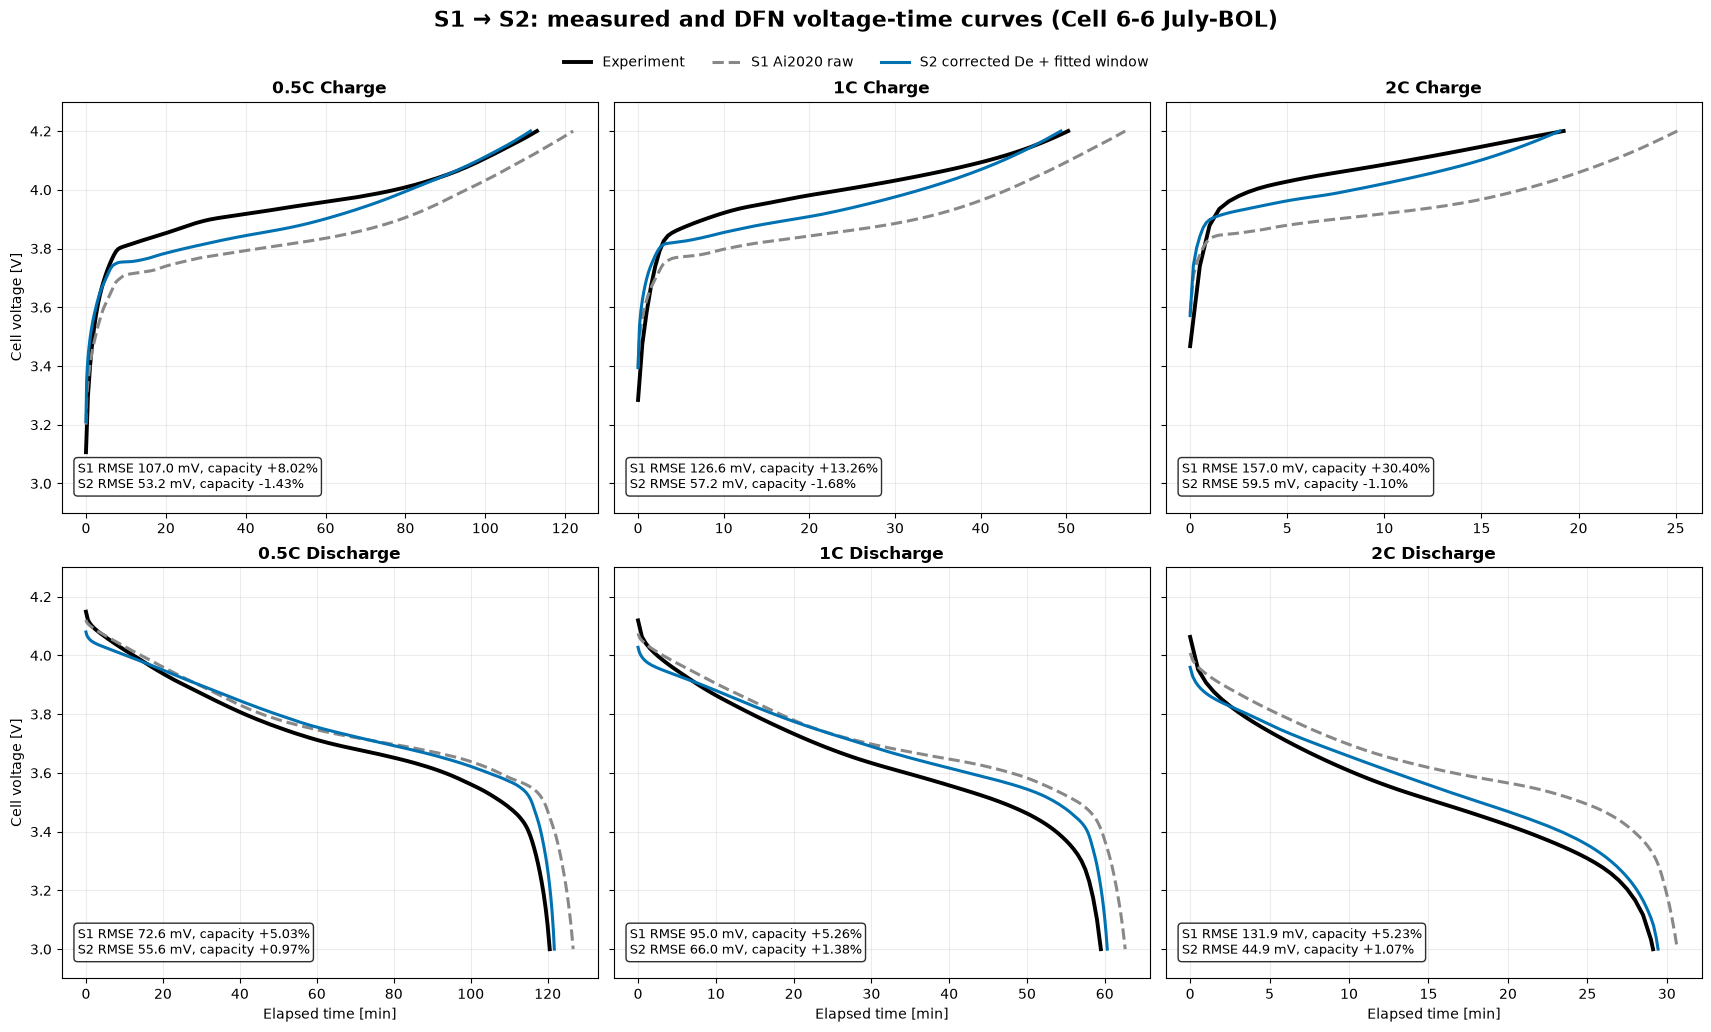

In [9]:
# =====================================================================
# 8. 6개 전압-시간 곡선과 오차를 한 그림으로 비교
# =====================================================================
figure, axes = plt.subplots(
    2, 3, figsize=(17.0, 9.5), sharey=True, constrained_layout=True
)
for column_index, c_rate in enumerate(TESTED_C_RATES):
    for row_index, is_charge in enumerate((True, False)):
        direction = "Charge" if is_charge else "Discharge"
        axis = axes[row_index, column_index]
        experiment_output = dynamic_experiment[(c_rate, is_charge)]
        experiment_time_min = np.asarray(experiment_output["t_min"], dtype=float)
        experiment_time_min = experiment_time_min - experiment_time_min[0]
        axis.plot(
            experiment_time_min,
            experiment_output["V"],
            color="black",
            linewidth=2.8,
            label="Experiment",
        )

        annotation_lines = []
        for stage_name, stage_configuration in stages.items():
            simulation_output = simulation_results[(stage_name, c_rate, is_charge)]
            simulation_time_min = simulation_output["time_s"] / 60.0
            matching_metric = branch_metrics[
                (branch_metrics["Stage"] == stage_name)
                & np.isclose(branch_metrics["C_rate"], c_rate)
                & (branch_metrics["Direction"] == direction)
            ].iloc[0]
            axis.plot(
                simulation_time_min,
                simulation_output["V"],
                color=stage_configuration["color"],
                linestyle=stage_configuration["linestyle"],
                linewidth=2.2,
                label=stage_name,
            )
            short_name = "S1" if stage_name.startswith("S1") else "S2"
            annotation_lines.append(
                f"{short_name} RMSE {matching_metric.Full_time_RMSE_mV:.1f} mV, "
                f"capacity {matching_metric.Capacity_error_pct:+.2f}%"
            )

        axis.text(
            0.03,
            0.05,
            "\n".join(annotation_lines),
            transform=axis.transAxes,
            fontsize=9,
            va="bottom",
            bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.82},
        )
        axis.set_title(f"{c_rate:g}C {direction}", weight="bold")
        axis.set_ylim(2.9, 4.3)
        axis.grid(alpha=0.24)
        if row_index == 1:
            axis.set_xlabel("Elapsed time [min]")
        if column_index == 0:
            axis.set_ylabel("Cell voltage [V]")

handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.035),
)
figure.suptitle(
    "S1 → S2: measured and DFN voltage-time curves (Cell 6-6 July-BOL)",
    fontsize=16,
    weight="bold",
    y=1.07,
)
figure.savefig(result_directory / "s1_s2_time_voltage_comparison.png", dpi=220)
plt.show()

branch_metrics.to_csv(
    result_directory / "s1_s2_branch_metrics.csv", index=False, encoding="utf-8-sig"
)
direction_summary.to_csv(
    result_directory / "s1_s2_direction_summary.csv", index=False, encoding="utf-8-sig"
)
overall_summary.to_csv(
    result_directory / "s1_s2_overall_summary.csv", index=False, encoding="utf-8-sig"
)
window_comparison.to_csv(
    result_directory / "s1_s2_window_comparison.csv", index=False, encoding="utf-8-sig"
)
parameter_change_table.to_csv(
    result_directory / "s1_s2_parameter_changes.csv", index=False, encoding="utf-8-sig"
)


## 5. 이 단계에서의 결론과 다음 단계

1. **S1은 출발점**이다. Ai2020은 Enertech LCO–graphite cell의 geometry와 기본 전기화학 구조를 제공하지만, 원 논문의 실험 검증은 방전 중심이며 현재 셀의 고속충전 제약 최적화를 위해 모든 파라미터가 측정된 것은 아니다.
2. **S2는 정적 정합과 단위 일관성을 개선한다.** (D_e) 단위를 SI로 보정하고, Ai2020 원 OCP에서 C/50 qOCV에 맞는 stoichiometry window와 capacity-consistent inventory를 계산한다.
3. **S2의 방전 개선이 곧 충전 모델 완성을 뜻하지 않는다.** 같은 고정 parameter set으로 0.5C/1C/2C 충·방전을 교차검증했을 때 충전 전압 오차가 상대적으로 크게 남으면, 그 원인은 OCP branch/hysteresis, kinetics, solid diffusion, electrolyte transport 등 다음 단계에서 분리해 검토해야 한다.
4. 따라서 S2는 고속충전 protocol 최적화의 최종 모델이 아니라, **OCP·kinetic·transport 보정 전의 명확한 중간 baseline**으로 사용한다.

### 이전 S2b와 이번 S2가 완전히 같은 수치가 아닌 이유

기존 누적 비교의 `S2b`는 최종 선정된 `Ai2020 음극 + 기존 GITT 양극` 조합에서 얻은 window를 Ai2020 양·음극 OCP 모델에 옮겨 적용했다. 그 결과 중앙 10–70% RMSE가 충전 78.09 mV, 방전 12.53 mV로 크게 갈렸다. 이번 노트북은 요청 문구를 엄밀히 적용해 **Ai2020 음극 OCP + Ai2020 양극 OCP 자체에서 window를 다시 fitting**했다. 그러므로 이번 S2가 “원 Ai2020 OCP에서 최적화한 S2”의 재현 가능한 정의이며, 과거 S2b 수치를 그대로 기대하면 안 된다.

아래 검증 셀은 데이터·단위·window·실행 branch가 기대한 조건과 일치하는지 자동 확인한다.


In [10]:
# =====================================================================
# 9. 재현성·일관성 자동 점검
# =====================================================================
expected_window_from_previous_run = np.array(
    [0.0031795299, 0.9850660533, 0.4418236027, 0.8677683066]
)
assert len(branch_metrics) == 12, "S1/S2 각각 6개 branch가 모두 계산되어야 합니다."
assert np.isfinite(branch_metrics["Full_time_RMSE_mV"]).all()
assert np.isclose(
    corrected_diffusivity_at_reference / raw_diffusivity_at_reference,
    1e-4,
    rtol=1e-12,
)
assert fitted_window["x0"] < fitted_window["x100"]
assert fitted_window["y100"] < fitted_window["y0"]
assert fitting_diagnostics["constraint_violation"] < 1e-8
assert np.allclose(
    fitted_window_vector,
    expected_window_from_previous_run,
    atol=2e-3,
), "기존 Ai2020-OCP fitting 결과와 차이가 큽니다. 입력 데이터 또는 환경을 확인하세요."
assert (
    s2_charge.Center10_70_time_RMSE_mV
    > s2_discharge.Center10_70_time_RMSE_mV
), "기존 '충전 오차 > 방전 오차' 경향이 재현되지 않았습니다."

run_manifest = pd.DataFrame(
    {
        "Item": [
            "Notebook scope",
            "PyBaMM version",
            "Random seed",
            "C/50 charge branches",
            "C/50 discharge branches",
            "Dynamic validation branches",
            "Voltage metric domain",
            "Status",
        ],
        "Value": [
            "S1 raw Ai2020 → S2 corrected De + Ai2020-OCP window fit",
            pybamm.__version__,
            RANDOM_SEED,
            int(low_rate_target["n_charge"]),
            int(low_rate_target["n_discharge"]),
            len(branch_metrics),
            "common elapsed time; center = 10–70% Qcell",
            "PASS",
        ],
    }
)
run_manifest.to_csv(
    result_directory / "run_manifest.csv", index=False, encoding="utf-8-sig"
)
display(run_manifest)
print("모든 자동 검증을 통과했습니다.")


,Item,Value
0,Notebook scope,S1 raw Ai2020 → S2 corrected De + Ai2020-OCP w...
1,PyBaMM version,26.7.1.0
2,Random seed,261019
3,C/50 charge branches,8
4,C/50 discharge branches,8
5,Dynamic validation branches,12
6,Voltage metric domain,common elapsed time; center = 10–70% Qcell
7,Status,PASS


모든 자동 검증을 통과했습니다.
